In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('CAR DETAILS FROM CAR DEKHO.csv')
print(df.shape)
print(list(df.columns))
df.head()

(4340, 8)
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [14]:
print(df.dtypes)
print()
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
for col in ['fuel', 'seller_type', 'transmission', 'owner']:
    print()
    print(df[col].value_counts())

name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Duplicates: 763

fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


In [15]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Removed", rows_before - len(df), "duplicate rows")

for col in ['name', 'fuel', 'seller_type', 'transmission', 'owner']:
    df[col] = df[col].str.strip().str.title()

Removed 763 duplicate rows


In [16]:
df['car_age'] = df['year'].max() - df['year']
df['brand'] = df['name'].str.split().str[0]

top_brands = df['brand'].value_counts().head(10).index
df['brand'] = df['brand'].where(df['brand'].isin(top_brands), 'Other')
df[['name', 'brand', 'year', 'car_age']].head()

,name,brand,year,car_age
0,Maruti 800 Ac,Maruti,2007,13
1,Maruti Wagon R Lxi Minor,Maruti,2007,13
2,Hyundai Verna 1.6 Sx,Hyundai,2012,8
3,Datsun Redigo T Option,Other,2017,3
4,Honda Amaze Vx I-Dtec,Honda,2014,6


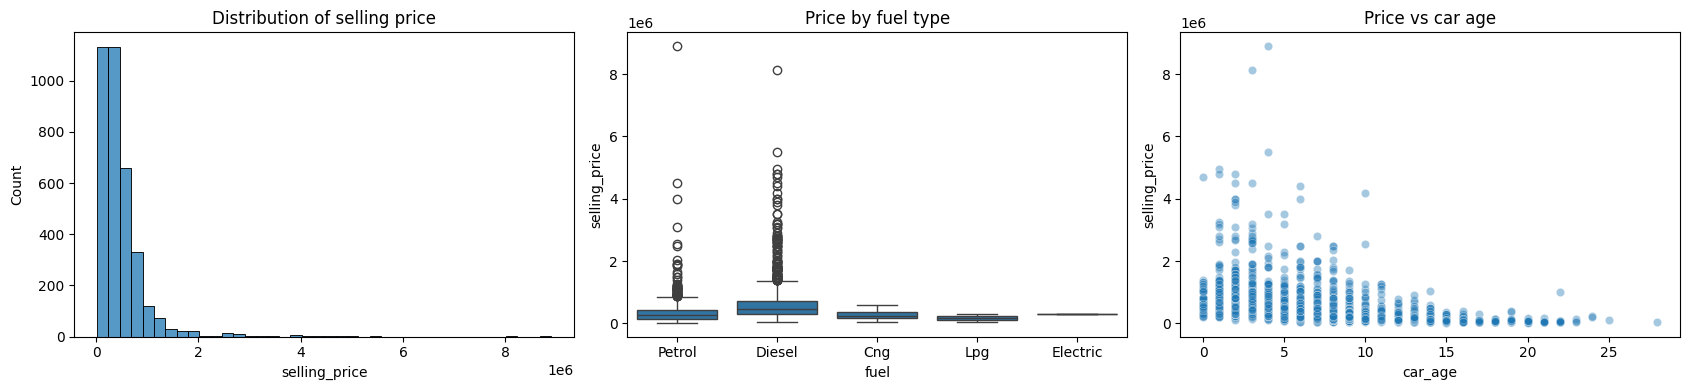

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df['selling_price'], bins=40, ax=axes[0])
axes[0].set_title('Distribution of selling price')
sns.boxplot(data=df, x='fuel', y='selling_price', ax=axes[1])
axes[1].set_title('Price by fuel type')
sns.scatterplot(data=df, x='car_age', y='selling_price', alpha=0.4, ax=axes[2])
axes[2].set_title('Price vs car age')
plt.tight_layout()
plt.show()

In [18]:
df_model = df.drop(columns=['name', 'year'])
df_model = pd.get_dummies(df_model,
                          columns=['fuel', 'seller_type', 'transmission', 'owner', 'brand'],
                          drop_first=True, dtype=int)
print(df_model.shape)

(3577, 24)


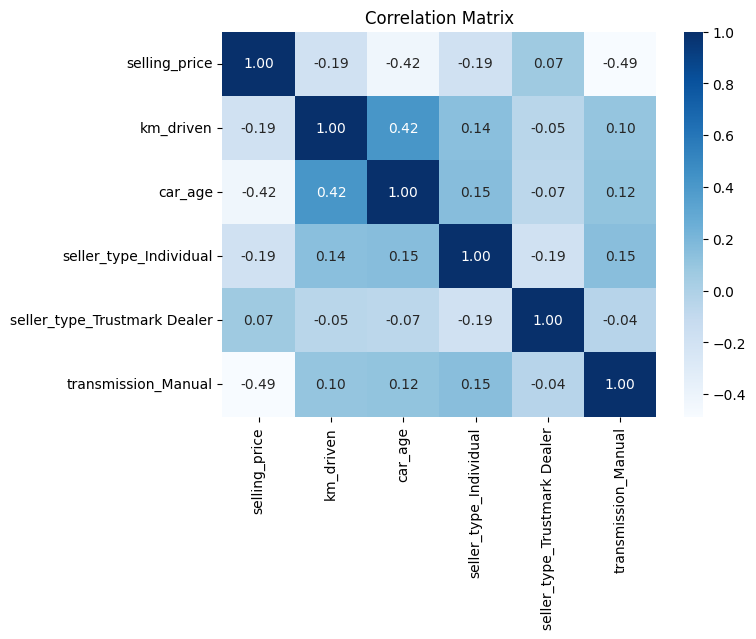

In [19]:
core = ['selling_price', 'km_driven', 'car_age'] + \
       [c for c in df_model.columns if c.startswith(('transmission_', 'seller_type_'))]
plt.figure(figsize=(7, 5))
sns.heatmap(df_model[core].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

X = df_model.drop(columns='selling_price')
y = df_model['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained")

Linear Regression trained
Random Forest trained
Gradient Boosting trained


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rows = []
for name, model in models.items():
    p = model.predict(X_test)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p)})
results_df = pd.DataFrame(rows).round(3)
results_df

,Model,MAE,RMSE,R2
0,Linear Regression,202149.170,422489.949,0.446
1,Random Forest,156889.715,325537.463,0.671
2,Gradient Boosting,151535.304,314596.699,0.693


Best model: Gradient Boosting


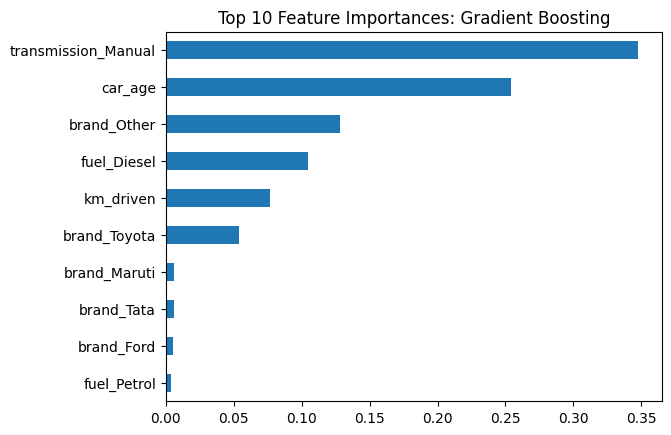

In [22]:
best_name = results_df.sort_values('R2', ascending=False).iloc[0]['Model']
best_model = models[best_name]
print("Best model:", best_name)

if hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values().tail(10)
    imp.plot(kind='barh', title=f'Top 10 Feature Importances: {best_name}')
    plt.show()

In [23]:
dups_removed = rows_before - len(df)
best = results_df.sort_values('R2', ascending=False).iloc[0]
age_corr = df['selling_price'].corr(df['car_age'])
fuel_med = df.groupby('fuel')['selling_price'].median().sort_values(ascending=False)

table = "\n".join(
    f"| {r.Model} | {r.MAE:,.0f} | {r.RMSE:,.0f} | {r.R2:.3f} |"
    for r in results_df.itertuples()
)
if hasattr(best_model, 'feature_importances_'):
    top3 = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(3)
    top3_text = ", ".join(f"{n} ({v:.0%})" for n, v in top3.items())
else:
    top3_text = "see the feature importance chart"

insights = f"""- Cleaning: removed {dups_removed} duplicate rows and standardised the text in the categorical columns (for example, different capitalisation of fuel types).
- Car age has a correlation of {age_corr:.2f} with selling price, so older cars sell for less.
- Median selling price by fuel type: {", ".join(f"{k} {v:,.0f}" for k, v in fuel_med.items())} (rupees).
- Best model: {best.Model} (R² {best.R2:.3f}, MAE {best.MAE:,.0f}, RMSE {best.RMSE:,.0f}).
- Most important features in the best model: {top3_text}."""

readme = f"""# Car Price Prediction with Machine Learning

**Oasis Infobyte Data Science Internship | Task 3**

## Objective
Build regression models that predict the selling price of a used car from features such as brand, age, kilometres driven, fuel type, seller type, transmission and owner history.

## Dataset
CarDekho used car listings from Kaggle ("Vehicle dataset"): {len(df)} cars after cleaning.

## Steps
1. Loaded the data and checked data types, missing values and duplicates
2. Cleaned the data: removed {dups_removed} duplicate rows and fixed inconsistent text values
3. Engineered features: car age (from the year column) and brand (from the car name)
4. Explored price distribution, price by fuel type and price against car age
5. One-hot encoded the categorical variables and built a correlation heatmap
6. Split the data 80/20 and trained Linear Regression, Random Forest and Gradient Boosting
7. Evaluated the models with MAE, RMSE and R², and charted feature importance for the best one

## Results
| Model | MAE | RMSE | R² |
|---|---|---|---|
{table}

## Key Insights
{insights}

## How to Run
1. Install the libraries: `pip3 install pandas numpy matplotlib seaborn scikit-learn jupyter`
2. Open `car_price_prediction.ipynb` in VS Code or Jupyter
3. Click Run All

## Screenshots
See the `screenshots` folder.
"""

print("===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====")
print(insights)
print()
print("===== README (paste into README.md) =====")
print(readme)

===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====
- Cleaning: removed 763 duplicate rows and standardised the text in the categorical columns (for example, different capitalisation of fuel types).
- Car age has a correlation of -0.42 with selling price, so older cars sell for less.
- Median selling price by fuel type: Diesel 475,000, Electric 310,000, Petrol 260,000, Cng 229,999, Lpg 180,000 (rupees).
- Best model: Gradient Boosting (R² 0.693, MAE 151,535, RMSE 314,597).
- Most important features in the best model: transmission_Manual (35%), car_age (25%), brand_Other (13%).

===== README (paste into README.md) =====
# Car Price Prediction with Machine Learning

**Oasis Infobyte Data Science Internship | Task 3**

## Objective
Build regression models that predict the selling price of a used car from features such as brand, age, kilometres driven, fuel type, seller type, transmission and owner history.

## Dataset
CarDekho used car listings from Kaggle ("V

### Observations

In [24]:
dups_removed = rows_before - len(df)
best = results_df.sort_values('R2', ascending=False).iloc[0]
age_corr = df['selling_price'].corr(df['car_age'])
fuel_med = df.groupby('fuel')['selling_price'].median().sort_values(ascending=False)

table = "\n".join(
    f"| {r.Model} | {r.MAE:,.0f} | {r.RMSE:,.0f} | {r.R2:.3f} |"
    for r in results_df.itertuples()
)
if hasattr(best_model, 'feature_importances_'):
    top3 = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(3)
    top3_text = ", ".join(f"{n} ({v:.0%})" for n, v in top3.items())
else:
    top3_text = "see the feature importance chart"

insights = f"""- Cleaning: removed {dups_removed} duplicate rows and standardised the text in the categorical columns (for example, different capitalisation of fuel types).
- Car age has a correlation of {age_corr:.2f} with selling price, so older cars sell for less.
- Median selling price by fuel type: {", ".join(f"{k} {v:,.0f}" for k, v in fuel_med.items())} (rupees).
- Best model: {best.Model} (R² {best.R2:.3f}, MAE {best.MAE:,.0f}, RMSE {best.RMSE:,.0f}).
- Most important features in the best model: {top3_text}."""

readme = f"""# Car Price Prediction with Machine Learning

**Oasis Infobyte Data Science Internship | Task 3**

## Objective
Build regression models that predict the selling price of a used car from features such as brand, age, kilometres driven, fuel type, seller type, transmission and owner history.

## Dataset
CarDekho used car listings from Kaggle ("Vehicle dataset"): {len(df)} cars after cleaning.

## Steps
1. Loaded the data and checked data types, missing values and duplicates
2. Cleaned the data: removed {dups_removed} duplicate rows and fixed inconsistent text values
3. Engineered features: car age (from the year column) and brand (from the car name)
4. Explored price distribution, price by fuel type and price against car age
5. One-hot encoded the categorical variables and built a correlation heatmap
6. Split the data 80/20 and trained Linear Regression, Random Forest and Gradient Boosting
7. Evaluated the models with MAE, RMSE and R², and charted feature importance for the best one

## Results
| Model | MAE | RMSE | R² |
|---|---|---|---|
{table}

## Key Insights
{insights}

## How to Run
1. Install the libraries: `pip3 install pandas numpy matplotlib seaborn scikit-learn jupyter`
2. Open `car_price_prediction.ipynb` in VS Code or Jupyter
3. Click Run All

## Screenshots
See the `screenshots` folder.
"""

print("===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====")
print(insights)
print()
print("===== README (paste into README.md) =====")
print(readme)

===== OBSERVATIONS (paste into a Markdown cell at the end of the notebook) =====
- Cleaning: removed 763 duplicate rows and standardised the text in the categorical columns (for example, different capitalisation of fuel types).
- Car age has a correlation of -0.42 with selling price, so older cars sell for less.
- Median selling price by fuel type: Diesel 475,000, Electric 310,000, Petrol 260,000, Cng 229,999, Lpg 180,000 (rupees).
- Best model: Gradient Boosting (R² 0.693, MAE 151,535, RMSE 314,597).
- Most important features in the best model: transmission_Manual (35%), car_age (25%), brand_Other (13%).

===== README (paste into README.md) =====
# Car Price Prediction with Machine Learning

**Oasis Infobyte Data Science Internship | Task 3**

## Objective
Build regression models that predict the selling price of a used car from features such as brand, age, kilometres driven, fuel type, seller type, transmission and owner history.

## Dataset
CarDekho used car listings from Kaggle ("V